In [1]:
%pip install -U langgraph langchain-groq

  Attempting uninstall: langgraph
    Found existing installation: langgraph 1.2.19
    Uninstalling langgraph-1.2.19:
      Successfully uninstalled langgraph-1.2.19
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [langgraph]


In [23]:
from langgraph.graph import StateGraph ,START,END
from langchain_groq import ChatGroq
from typing import TypedDict,Annotated,Literal
from langchain_core.messages import SystemMessage,HumanMessage,BaseMessage
from pydantic import BaseModel, Field
import operator
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver
from google.colab import userdata

In [7]:
class ChatState(TypedDict):
  messages: Annotated[list[BaseMessage],add_messages]

In [17]:
# Retrieve Groq API key from Colab Secrets
groq_api_key = userdata.get("GROQ_API_KEY")
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    api_key=groq_api_key
)

In [18]:
def chat_node(state:ChatState):
  messages=state['messages']
  response=llm.invoke(messages)
  return {'messages':[response]}

In [24]:
checkpointer=MemorySaver()

In [25]:
graph=StateGraph(ChatState)
graph.add_node('chat_node',chat_node)

graph.add_edge(START,'chat_node')
graph.add_edge('chat_node',END)

chatbot=graph.compile(checkpointer=checkpointer)


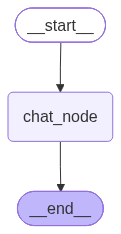

In [20]:
chatbot

In [21]:
initial_state = {
    'messages': [HumanMessage(content='What is the capital of india')]
}

chatbot.invoke(initial_state)['messages'][-1].content

'The capital of India is **New\u202fDelhi**.'

In [27]:
thread_id='1'

while True:
  user_message=input('Type here: ')
  print('User: ',user_message)
  if user_message.strip().lower() in ['exit','quit','bye']:
    break
  config={'configurable':{'thread_id':thread_id}}
  response=chatbot.invoke({'messages':[HumanMessage(content=user_message)]},config=config)
  print('AI: ',response['messages'][-1].content)

Type here: hello my name is pranjal
User:  hello my name is pranjal
AI:  Hello Pranjal! 👋 How can I help you today?
Type here: what is my name
User:  what is my name
AI:  Your name is Pranjal.
Type here: add 14 to 20
User:  add 14 to 20
AI:  14 + 20 = 34.
Type here: add 16 to it
User:  add 16 to it
AI:  34 + 16 = 50.
Type here: bye
User:  bye


In [28]:
chatbot.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='hello my name is pranjal', additional_kwargs={}, response_metadata={}, id='09cda50b-5fdf-4e77-84af-85df955a925e'), AIMessage(content='Hello Pranjal! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'User says "hello my name is pranjal". We should respond politely, maybe ask how can help.'}, response_metadata={'token_usage': {'completion_tokens': 46, 'prompt_tokens': 78, 'total_tokens': 124, 'completion_time': 0.047729105, 'completion_tokens_details': {'reasoning_tokens': 23}, 'prompt_time': 0.003751796, 'prompt_tokens_details': None, 'queue_time': 0.075016954, 'total_time': 0.051480901}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_816fc87d18', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1b631-b97e-70a7-bc08-4425dd5337b7-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 78, 'output_tokens': 46, 'tota